# Temporal Analysis & Autocorrelation

## Objective

The objective of this analysis is to investigate how
historical charging station availability can be used
to predict future availability.

The analysis focuses on temporal stability,
autocorrelation, prediction horizons, and the
identification of potential lag features for machine
learning models.

## Dataset

- 100 selected EV charging stations
- December 1, 2022 – February 28, 2023
- 5-minute temporal resolution
- 2,592,000 expected observations
- Shared data loader

In [190]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

sys.path.append("../src")
import data_loader as dl

In [191]:
from pathlib import Path

tables_dir = Path("../outputs/tables")
figures_dir = Path("../outputs/figures")

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

In [192]:
data_path = Path.home() / "VoltAhead" / "data" / "UrbanEVDataset" / "20220901-20230228_station-raw" / "charge_5min"

print(data_path.exists())

True


## 0. Data Loading

The shared dataset is loaded using the project's
data loader.

The idle variable represents the number of available
charging points at each station.

Each column represents a charging station, and each
row represents a 5-minute timestamp.

Missing observations are preserved as NaN.

In [193]:
idle_data = dl.load_stations_wide(variable="idle")

idle_data.head()

station_id,1703,1712,1714,1717,1718,1720,1721,1729,1730,1743,...,1966,1967,1968,1971,1972,1975,1980,1981,1988,1992
time,,,,,,,,,,,,,,,,,,,,,
2022-12-01 00:00:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,12.0
2022-12-01 00:05:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,7.0
2022-12-01 00:10:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,7.0
2022-12-01 00:15:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,6.0
2022-12-01 00:20:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,6.0


In [194]:
print("Dataset shape:", idle_data.shape)
print("Number of stations:", idle_data.columns.nunique())
print("Number of timestamps:", len(idle_data))
print("Start date:", idle_data.index.min())
print("End date:", idle_data.index.max())

print("Correct time grid:",
      idle_data.index.equals(dl.expected_index()))

print("Correct station IDs:",
      set(idle_data.columns) == set(dl.list_station_ids()))

Dataset shape: (25920, 100)
Number of stations: 100
Number of timestamps: 25920
Start date: 2022-12-01 00:00:00
End date: 2023-02-28 23:55:00
Correct time grid: True
Correct station IDs: True


## 1. Consecutive Observation Analysis

This analysis investigates how frequently the number
of available charging points remains unchanged
between consecutive 5-minute observations.

Only pairs with valid observations at both
timestamps are included.

The analysis is performed across all 100 selected
charging stations.

In [195]:
previous_idle = idle_data.shift(1)

valid_pairs = (
    idle_data.notna() & previous_idle.notna()
)

unchanged = (
    (idle_data == previous_idle) & valid_pairs
)

previous_idle.head()

station_id,1703,1712,1714,1717,1718,1720,1721,1729,1730,1743,...,1966,1967,1968,1971,1972,1975,1980,1981,1988,1992
time,,,,,,,,,,,,,,,,,,,,,
2022-12-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-12-01 00:05:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,12.0
2022-12-01 00:10:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,7.0
2022-12-01 00:15:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,7.0
2022-12-01 00:20:00,2.0,3.0,6.0,5.0,NaN,7.0,NaN,1.0,14.0,2.0,...,28.0,10.0,17.0,8.0,6.0,4.0,21.0,11.0,6.0,6.0


In [196]:
total_valid_pairs = valid_pairs.sum().sum()
total_unchanged = unchanged.sum().sum()

unchanged_rate = (
    total_unchanged / total_valid_pairs
) * 100

changed_rate = 100 - unchanged_rate

print("Valid observation pairs:", total_valid_pairs)
print("Unchanged pairs:", total_unchanged)
print(f"Unchanged rate: {unchanged_rate:.2f}%")
print(f"Changed rate: {changed_rate:.2f}%")

Valid observation pairs: 1931527
Unchanged pairs: 1881818
Unchanged rate: 97.43%
Changed rate: 2.57%


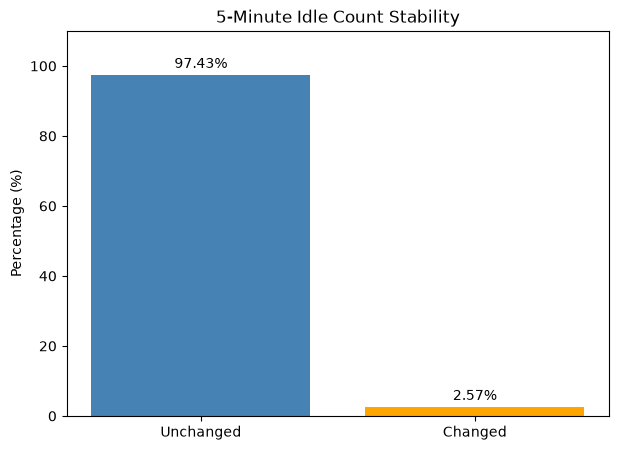

In [197]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Unchanged", "Changed"],
    [unchanged_rate, changed_rate],
    color=["steelblue", "orange"]
)

plt.ylabel("Percentage (%)")
plt.title("5-Minute Idle Count Stability")
plt.ylim(0, 110)

for i, value in enumerate([unchanged_rate, changed_rate]):
    plt.text(i, value + 2, f"{value:.2f}%", ha="center")

plt.show()

### 1.1 Station-Level Stability

The overall stability rate is calculated across all
valid observation pairs.

Station-level stability is also examined to determine
whether temporal stability is consistent across
different charging stations.

In [198]:
station_stability = (
    unchanged.sum() / valid_pairs.sum()
) * 100

station_stability.describe()

count     99.000000
mean      97.327149
std        2.518082
min       88.545083
25%       96.230423
50%       98.371851
75%       99.111898
max      100.000000
dtype: float64

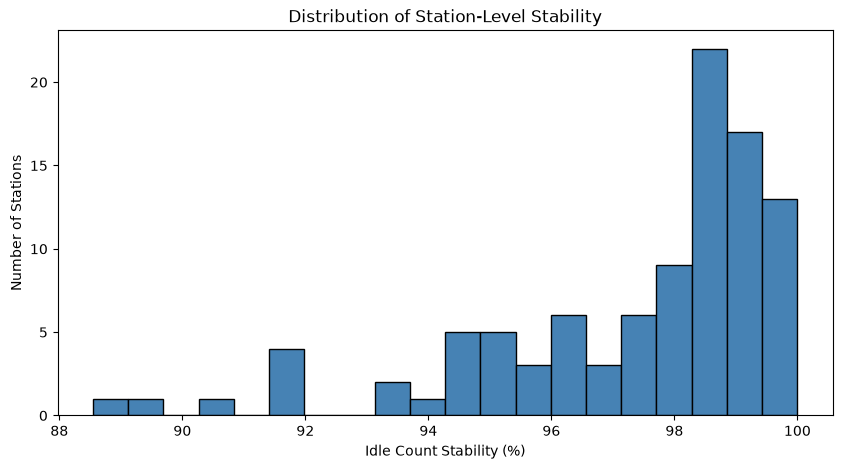

In [199]:
plt.figure(figsize=(10, 5))

plt.hist(
    station_stability.dropna(),
    bins=20,
    edgecolor="black",
    color="steelblue"
)

plt.xlabel("Idle Count Stability (%)")
plt.ylabel("Number of Stations")
plt.title("Distribution of Station-Level Stability")

plt.show()

### Findings

- A total of 1,931,527 valid consecutive observation
  pairs were analyzed.
- The number of available charging points remained
  unchanged in 97.43% of these pairs.
- Only 2.57% of consecutive observations showed
  a change in idle count.
- Most stations exhibited stability rates between
  95% and 100%.
- High short-term temporal stability is observed
  across the selected charging stations.

These findings suggest that recent idle values may
be useful features for future availability prediction.

However, further analysis is required to determine
whether this temporal relationship persists over
longer prediction horizons.

## 2. Temporal Autocorrelation Analysis

Autocorrelation measures the correlation between
a time series and its own lagged values.

The objective is to investigate how strongly
historical idle counts are related to current
idle counts at different time lags.

The following time lags are examined:

- 5 minutes
- 10 minutes
- 15 minutes
- 30 minutes
- 40 minutes
- 60 minutes
- 120 minutes

Autocorrelation is calculated separately for each
station to preserve station-specific temporal
relationships.

In [200]:
lags_minutes = [5, 10, 15, 30, 40, 60, 120]

autocorr_results = {}

for minutes in lags_minutes:
    lag = minutes // 5

    autocorr_results[minutes] = idle_data.apply(
        lambda station: station.autocorr(lag=lag)
    )

autocorr_df = pd.DataFrame(autocorr_results)

autocorr_df.head()

,5,10,15,30,40,60,120
station_id,,,,,,,
1703,0.970840,0.952705,0.935825,0.886729,0.851971,0.783962,0.596447
1712,0.973136,0.959911,0.945963,0.912634,0.885293,0.830075,0.689871
1714,0.981979,0.975966,0.966278,0.943331,0.924902,0.883399,0.733957
1717,0.969317,0.973282,0.953721,0.944384,0.931282,0.904380,0.824967
1718,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Average Autocorrelation Across Stations

The mean and median autocorrelation values are
calculated for each time lag across stations.

Undefined autocorrelation values are excluded
from the calculations.

Each station with a defined autocorrelation
contributes equally to the mean.

In [201]:
autocorr_summary = pd.DataFrame({
    "Mean": autocorr_df.mean(),
    "Median": autocorr_df.median(),
    "Std": autocorr_df.std(),
    "Valid Stations": autocorr_df.count()
})

autocorr_summary.index.name = "Lag (minutes)"

autocorr_summary.round(4)

,Mean,Median,Std,Valid Stations
Lag (minutes),,,,
5,0.9209,0.9546,0.0899,99
10,0.9057,0.9428,0.0999,99
15,0.8885,0.9267,0.1116,99
30,0.8667,0.9049,0.1096,99
40,0.8516,0.8878,0.1146,99
60,0.7995,0.8402,0.1433,99
120,0.6902,0.7437,0.2197,98


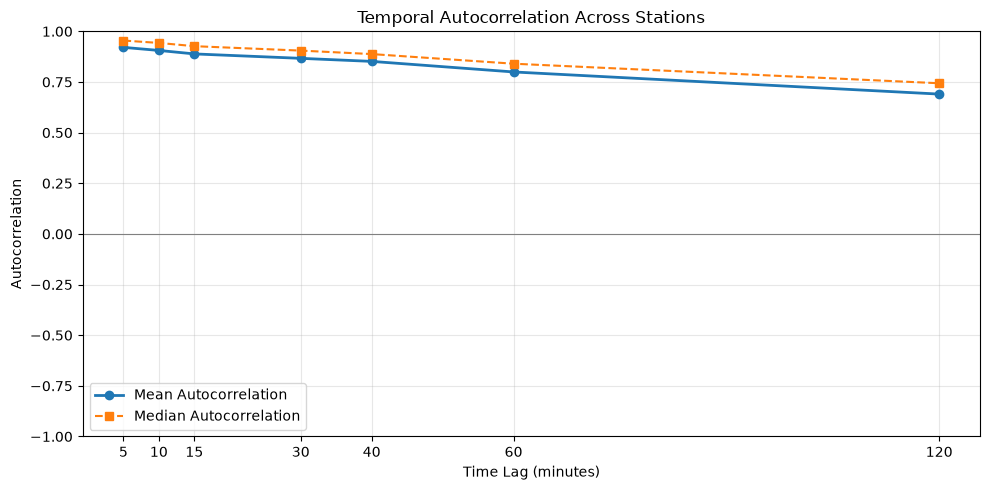

In [202]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    autocorr_summary.index,
    autocorr_summary["Mean"],
    marker="o",
    linewidth=2,
    label="Mean Autocorrelation"
)

ax.plot(
    autocorr_summary.index,
    autocorr_summary["Median"],
    marker="s",
    linestyle="--",
    label="Median Autocorrelation"
)

ax.set_xlabel("Time Lag (minutes)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Temporal Autocorrelation Across Stations")

ax.set_xticks(lags_minutes)
ax.set_ylim(-1, 1)
ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    figures_dir / "temporal_autocorrelation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Findings

- The mean autocorrelation is 0.9209 at the
  5-minute lag, indicating strong short-term
  temporal dependency.

- Mean autocorrelation gradually decreases
  as the time lag increases.

- At the target prediction horizons of 30, 40,
  and 60 minutes, mean autocorrelation values
  are 0.8667, 0.8516, and 0.7995, respectively.

- Positive temporal dependency persists even
  at the 120-minute lag, with a mean
  autocorrelation of 0.6902.

- Station-level variability generally increases
  at longer time lags.

- Autocorrelation is defined for 99 stations
  at lags up to 60 minutes and 98 stations
  at the 120-minute lag.

These findings support the consideration of
historical idle counts as candidate lag features
for future availability prediction.

However, autocorrelation does not directly
measure prediction accuracy or guarantee
model performance.

## 3. Current vs. Future Availability Analysis

This analysis investigates the relationship between
current and future station availability across
different prediction horizons.

Availability is represented as a binary variable:

- 1: At least one charging point is available.
- 0: No charging points are available.
- NaN: Availability is unknown.

In [203]:
availability_data = (idle_data > 0).astype(float)

availability_data = availability_data.where(
    idle_data.notna()
)

availability_data.head()

station_id,1703,1712,1714,1717,1718,1720,1721,1729,1730,1743,...,1966,1967,1968,1971,1972,1975,1980,1981,1988,1992
time,,,,,,,,,,,,,,,,,,,,,
2022-12-01 00:00:00,1.0,1.0,1.0,1.0,NaN,1.0,NaN,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2022-12-01 00:05:00,1.0,1.0,1.0,1.0,NaN,1.0,NaN,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2022-12-01 00:10:00,1.0,1.0,1.0,1.0,NaN,1.0,NaN,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2022-12-01 00:15:00,1.0,1.0,1.0,1.0,NaN,1.0,NaN,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2022-12-01 00:20:00,1.0,1.0,1.0,1.0,NaN,1.0,NaN,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 3.2 Availability Transition Analysis

Availability transitions are examined by comparing
the current availability status with the future
availability status of the same station.

Only pairs with valid observations at both
timestamps are included.

In [204]:
horizon = 30
lag = horizon // 5

future_availability = availability_data.shift(-lag)

valid_future_pairs = (
    availability_data.notna()
    & future_availability.notna()
)

In [205]:
n11 = (
    (availability_data == 1)
    & (future_availability == 1)
    & valid_future_pairs
).sum().sum()

n10 = (
    (availability_data == 1)
    & (future_availability == 0)
    & valid_future_pairs
).sum().sum()

n01 = (
    (availability_data == 0)
    & (future_availability == 1)
    & valid_future_pairs
).sum().sum()

n00 = (
    (availability_data == 0)
    & (future_availability == 0)
    & valid_future_pairs
).sum().sum()

transition_counts = pd.DataFrame(
    [[n11, n10], [n01, n00]],
    index=["Current Available", "Current Unavailable"],
    columns=["Future Available", "Future Unavailable"]
)

transition_counts

,Future Available,Future Unavailable
Current Available,1848731,4114
Current Unavailable,4093,72329


In [206]:
transition_probabilities = transition_counts.div(
    transition_counts.sum(axis=1),
    axis=0
) * 100

transition_probabilities.round(2)

,Future Available,Future Unavailable
Current Available,99.78,0.22
Current Unavailable,5.36,94.64


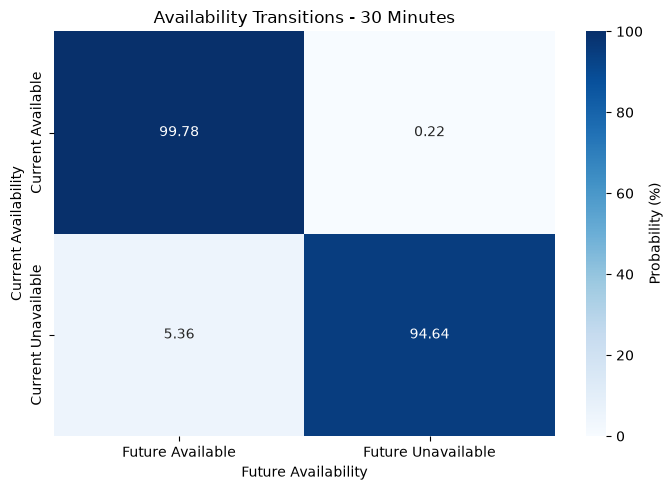

In [207]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    transition_probabilities,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Probability (%)"}
)

plt.title("Availability Transitions - 30 Minutes")
plt.xlabel("Future Availability")
plt.ylabel("Current Availability")

plt.tight_layout()
plt.show()

### Findings – 30-Minute Prediction Horizon

- Currently available stations remain available
  after 30 minutes in 99.78% of valid cases.

- Currently unavailable stations remain unavailable
  in 94.64% of valid cases.

- The probability of an unavailable station
  becoming available is 5.36%.

- The probability of an available station
  becoming unavailable is 0.22%.

These results indicate strong temporal persistence
in binary station availability.

Current availability is therefore a promising
predictive feature.

However, the high persistence rates also highlight
the importance of comparing future machine learning
models against a simple persistence baseline.

## 4. Prediction Horizon Analysis

This analysis examines how availability transition
probabilities change as the prediction horizon
increases.

Prediction horizons of 5, 10, 15, 30, 40, 60,
and 120 minutes are evaluated.

The objective is to determine how long the current
availability status remains informative for future
availability prediction.

In [208]:
horizons = [5, 10, 15, 30, 40, 60, 120]

horizon_results = []

for horizon in horizons:

    lag = horizon // 5

    future = availability_data.shift(-lag)

    valid = availability_data.notna() & future.notna()

    n11 = (
        (availability_data == 1)
        & (future == 1) & valid
    ).sum().sum()

    n10 = (
        (availability_data == 1)
        & (future == 0) & valid
    ).sum().sum()

    n01 = (
        (availability_data == 0)
        & (future == 1) & valid
    ).sum().sum()

    n00 = (
        (availability_data == 0)
        & (future == 0) & valid
    ).sum().sum()

    horizon_results.append({
        "Horizon": horizon,
        "Available → Available": n11 / (n11 + n10) * 100,
        "Available → Unavailable": n10 / (n11 + n10) * 100,
        "Unavailable → Available": n01 / (n01 + n00) * 100,
        "Unavailable → Unavailable": n00 / (n01 + n00) * 100,
        "Valid Pairs": n11 + n10 + n01 + n00
    })

horizon_df = pd.DataFrame(horizon_results)

horizon_df.round(2)

,Horizon,Available → Available,Available → Unavailable,Unavailable → Available,Unavailable → Unavailable,Valid Pairs
0,5,99.88,0.12,2.84,97.16,1931527
1,10,99.86,0.14,3.47,96.53,1931070
2,15,99.83,0.17,4.17,95.83,1930616
3,30,99.78,0.22,5.36,94.64,1929267
4,40,99.75,0.25,6.04,93.96,1928379
5,60,99.68,0.32,7.71,92.29,1926624
6,120,99.52,0.48,11.49,88.51,1923573


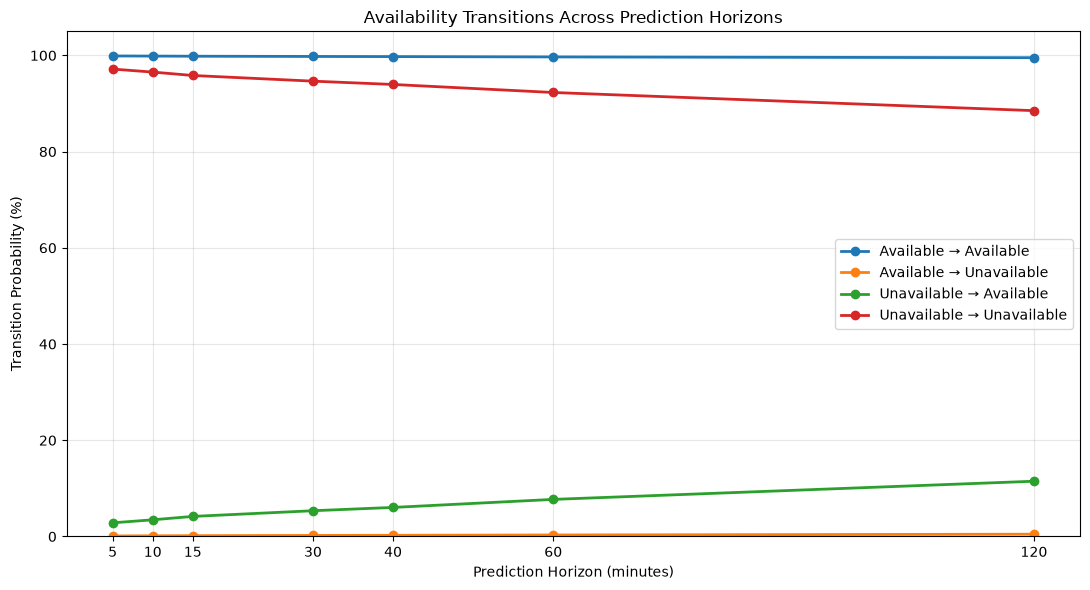

In [209]:
plt.figure(figsize=(11, 6))

for column in horizon_df.columns[1:5]:

    plt.plot(
        horizon_df["Horizon"],
        horizon_df[column],
        marker="o",
        linewidth=2,
        label=column
    )

plt.xlabel("Prediction Horizon (minutes)")
plt.ylabel("Transition Probability (%)")
plt.title("Availability Transitions Across Prediction Horizons")

plt.xticks(horizons)
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### Findings

- Available stations show strong temporal persistence
  across all prediction horizons.

- The probability of an unavailable station becoming
  available increases as the prediction horizon increases.

- Current availability remains informative even at
  longer prediction horizons.

- Availability transitions are asymmetric: currently
  available stations are more likely to retain their
  status than currently unavailable stations.

- These findings support the inclusion of current
  availability and historical occupancy features
  in the prediction model.

## 5. Baseline Analysis

Two simple baselines are evaluated to establish
reference performance levels for future machine
learning models.

- Persistence baseline: predicts that future
  availability will equal current availability.

- Majority class baseline: always predicts the
  most frequent availability class.

The analysis also investigates the potential
impact of class imbalance.

In [210]:
# Preserve missing observations
availability_data = (idle_data > 0).where(idle_data.notna())

baseline_results = []

for horizon in horizons:

    lag = horizon // 5

    future = availability_data.shift(-lag)

    valid = availability_data.notna() & future.notna()

    total = valid.sum().sum()

    correct = (
        (availability_data == future) & valid
    ).sum().sum()

    available = (
        (future == 1) & valid
    ).sum().sum()

    unavailable = (
        (future == 0) & valid
    ).sum().sum()

    baseline_results.append({
        "Horizon": horizon,
        "Persistence Accuracy (%)": correct / total * 100,
        "Majority Accuracy (%)": max(available, unavailable) / total * 100,
        "Available (%)": available / total * 100,
        "Unavailable (%)": unavailable / total * 100,
        "Valid Pairs": total
    })

baseline_df = pd.DataFrame(baseline_results)

baseline_df.round(2)

,Horizon,Persistence Accuracy (%),Majority Accuracy (%),Available (%),Unavailable (%),Valid Pairs
0,5,99.77,96.03,96.03,3.97,1931527
1,10,99.72,96.03,96.03,3.97,1931070
2,15,99.67,96.04,96.04,3.96,1930616
3,30,99.57,96.04,96.04,3.96,1929267
4,40,99.52,96.04,96.04,3.96,1928379
5,60,99.39,96.04,96.04,3.96,1926624
6,120,99.09,96.04,96.04,3.96,1923573


### Findings

- The persistence baseline achieves an accuracy
  between 99.09% and 99.77% across the investigated
  prediction horizons.

- The majority class baseline achieves approximately
  96% accuracy due to the highly imbalanced
  availability distribution.

- Approximately 96% of valid future observations
  are available, while only 4% are unavailable.

- Persistence consistently outperforms the majority
  class baseline.

- Current availability provides a strong reference
  for future availability prediction.

- Accuracy alone is insufficient for evaluating
  machine learning models on this dataset.

- Future model evaluation should include precision,
  recall, F1-score, and balanced accuracy.

## 6. Candidate Lag Feature Selection

Based on the temporal autocorrelation analysis,
historical idle counts are identified as candidate
features for future availability prediction.

The investigated lag features are 5, 10, 15, 30,
40, 60, and 120 minutes.

Short-term lags exhibit stronger autocorrelation,
while longer-term lags retain substantial temporal
information.

Final feature selection will be performed during
model development and validation.

In [211]:
lag_feature_summary = pd.DataFrame({
    "Feature": [
        f"idle_lag_{minutes}"
        for minutes in lags_minutes
    ],
    "Lag (minutes)": lags_minutes,
    "Mean Autocorrelation": autocorr_summary["Mean"].values
})

lag_feature_summary.round(4)

,Feature,Lag (minutes),Mean Autocorrelation
0,idle_lag_5,5,0.9209
1,idle_lag_10,10,0.9057
2,idle_lag_15,15,0.8885
3,idle_lag_30,30,0.8667
4,idle_lag_40,40,0.8516
5,idle_lag_60,60,0.7995
6,idle_lag_120,120,0.6902


## 7. Overall Conclusion

The temporal analysis was conducted on 100 selected EV
charging stations using 90 days of historical data
with a 5-minute temporal resolution.

### Key Findings

- The number of available charging points remains
  unchanged in 97.43% of valid consecutive
  observations.

- Mean autocorrelation decreases from 0.9209 at
  5 minutes to 0.6902 at 120 minutes, indicating
  strong temporal dependence.

- Mean autocorrelation remains high at the main
  prediction horizons of 30, 40, and 60 minutes.

- Currently available stations are highly likely
  to remain available at future timestamps.

- The probability of unavailable stations becoming
  available increases with the prediction horizon.

- The persistence baseline achieves approximately
  99% accuracy across all investigated horizons.

- The dataset exhibits substantial class imbalance,
  with approximately 96% available observations
  among valid prediction pairs.

### Implications for Model Development

Current availability and historical idle counts
are promising candidate features for future
availability prediction.

The investigated lag features are 5, 10, 15,
30, 40, 60, and 120 minutes.

Future models should be compared against the
persistence baseline using chronological
training and testing splits.

Evaluation should include class-specific metrics
and balanced accuracy rather than accuracy alone.

The final contribution of each lag feature must
be verified during model validation.

## 8. Export Results

The numerical results are exported as CSV files for project reporting and future model development.

All visualizations are retained within the notebook.

In [212]:
from pathlib import Path

tables_dir = Path("../outputs/tables")
tables_dir.mkdir(parents=True, exist_ok=True)

autocorr_df.to_csv(
    tables_dir / "temporal_autocorrelation_by_station.csv"
)

autocorr_summary.to_csv(
    tables_dir / "temporal_autocorrelation_summary.csv"
)

baseline_df.to_csv(
    tables_dir / "temporal_baseline_results.csv",
    index=False
)

lag_feature_summary.to_csv(
    tables_dir / "temporal_lag_features.csv",
    index=False
)

print("All temporal analysis tables exported successfully.")

All temporal analysis tables exported successfully.
